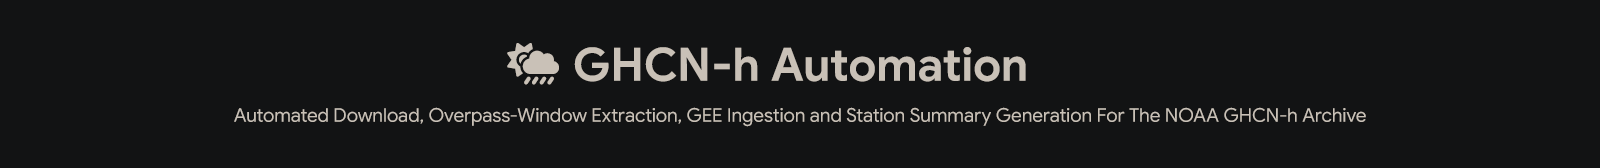

| | |
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |
| **Source-Data Licence** | GHCNh is a U.S. Government work in the public domain (NOAA/NCEI) |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

---

#### **Overview**

GHCN-hourly (GHCN-h) is NOAA/NCEI's archive of surface meteorological observations at sub-daily resolution. This notebook turns the raw per-station yearly PSV files into the two sets used by the ERA5-Land bias correction and downscaling validation: a per-city observation CSV, and a per-city station-summary CSV documenting which stations contributed to the analysis.

| Step | Section | What Happens |
|:--:|:--|:--|
| 1 | §4 | Station IDs are resolved by spatial intersection between `GHCNh-Station-List` and each city's Complete domains. |
| 2 | §5 | Per-city season tables (calendar dates) are generated from compact templates. |
| 3 | §6 | A dry-run plan lists how many station-year files are needed, which are already cached, and how many still have to be fetched. |
| 4 | §7 | Downloads (cache-backed, resumable on retry) → per-day closest-observation extraction → per-city CSV. |
| 5 | §8 | A per-season station summary is built, deduplicating stations per ERA5-Land pixel (grid definition read from Earth Engine). |
| 6 | §9 (Optional) | Station list and per-city CSVs are ingested as Earth Engine assets, if not already done elsewhere. |
| 7 | §10 | Row counts, station coverage, and file integrity are audited. |

#### **Products**

[1] **`GHCN-h/{City}.csv`** : The single observation per station per day closest to the city's satellite-overpass hour (§3.4), within ±`OverpassToleranceMin` (30 min), for every configured station and season. Columns: `GHCNID, StationName, Date, Hour_UTC, Obs_Time_UTC, Offset_Min, Season, T2M, D2M, RH, WS10M`.

[2] **`Station Summary/{City}.csv`** : One row per retained station, with coordinate/elevation metadata and the observation count per season (Tehran: Spring/Summer/Autumn/Winter; Singapore: NEM/IM1/SWM/IM2) plus a cross-season total.

#### **Cache**
A single station-year PSV file serves every season overlapping that year. The notebook caches each download at `<BaseDir>/Cache/<Year>/GHCNh_<StationID>_<Year>.psv` and reuses it across seasons and re-runs. The cache is safe to delete at any time.

---

#### **Before You Begin**

[1] **The GHCN-h station list** (`GHCNh-Station-List.csv`), with columns `GHCN_ID, LATITUDE, LONGITUDE, ELEVATION, NAME`.

[2] **Earth Engine Domain Assets:** for each city's Complete and Holdout Domains. These are read via `ResolveGEEDomain()` in §4; no local shapefiles are required.

[3] **Earth Engine Access:** to the project set in `GEEProject` (§2). §9 can ingest the station list and per-city observation tables for the Earth Engine scripts (ERA5-Land bias correction and downscaling); if they are already there from another step, leave `EnableGEEIngestion = False` and skip §9.

[4] **Disk Space:** The cache for the default 6 years × 2 cities is under 1 GB; §6 reports the exact size.

**Suggested Workflow:** Run once with `RunMode = "Test"` (one city, one year) to confirm connectivity, then switch to `"Production"`. Files already in the cache are reused on every re-run.

---

#### **[1] Environment**

In [1]:
# ———————————————
# [1] Environment
# ———————————————

import os

import shutil

try:

    from google.colab import drive

except ImportError:

    drive = None

if drive is not None:

    drive.mount( "/content/drive" , force_remount = True )

import importlib.util

import subprocess

import sys

for PackageName in ( "geeup" , "pycountry" , "geonamescache" ):
    
    if importlib.util.find_spec(PackageName) is None:

        subprocess.check_call([ sys.executable , "-m" , "pip" , "install" , "-q" , PackageName ])

import datetime

import io

import platform

import tempfile

import time

from importlib import metadata

from pathlib import Path

import numpy as np

import pandas as pd

import requests

import urllib3

from requests.adapters import HTTPAdapter

from urllib3.util.retry import Retry

import geopandas as gpd

import pycountry

import ee

from IPython.display import display

IsColab = "google.colab" in sys.modules

def PackageVersion(PackageName):

    """Return The Installed Version Of A Package, Or 'not installed'."""

    try:

        return metadata.version(PackageName)

    except metadata.PackageNotFoundError:

        return "not installed"

import logging

logging.getLogger('google_auth_httplib2').setLevel(logging.ERROR)

logging.getLogger('httplib2').setLevel(logging.ERROR)

logging.getLogger('googleapiclient').setLevel(logging.ERROR)

logging.getLogger('google.auth').setLevel(logging.ERROR)

# [1.1] Environment

print("\n———————————")
print("Environment")
print("———————————")

print(f"\n  Run Started (UTC) : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"\n  Platform          : {'Google Colab' if IsColab else platform.platform()}")

print(f"\n  Python            : {platform.python_version()}")

for PackageName in ( "pandas" , "geopandas" , "requests" , "pycountry" , "geonamescache" , "earthengine-api" , "geeup" ):

    print(f"\n  {PackageName:<18}: {PackageVersion(PackageName)}")

Mounted at /content/drive

———————————
Environment
———————————

  Run Started (UTC) : 2026-11-03 20:08:12

  Platform          : Google Colab

  Python            : 3.13.18

  pandas            : 2.2.3

  geopandas         : 1.2.0

  requests          : 2.32.4

  pycountry         : 26.2.16

  geonamescache     : 3.0.2

  earthengine-api   : 1.7.39

  geeup             : 2.0.0


---

#### **[2] Configuration**

| Setting | Purpose |
|:--|:--|
| `RunMode` | `"Test"` runs one city and one year; `"Production"` runs everything. |
| `CitiesByMode`, `YearsByMode` | Which cities and which calendar years to process. |
| `BaseDir` + `Paths` | The single base folder plus all file templates. Every other path is derived. |
| `GHCNhURLTemplate` | The NOAA/NCEI PSV endpoint (kept in one place so it can be updated when the archive moves). |
| `OverpassToleranceMin` | ± Minutes around the derived overpass hour that are eligible observations. The overpass hour itself is derived from VIIRS in §3.4. |
| `SeasonTemplates` | Compact season definitions: `(year_offset, month, day)`, with `day = None` meaning 'last day of month'. All season labels and date ranges are generated from this. |
| `CitiesToCountries` | Country names per city; only used to translate the GHCN station-ID prefix into an ISO3 code via `pycountry`. |
| `GEEProject`, `GEEAssetRoot`, etc. | Earth Engine project and asset templates for §8–§9. |
| `EnableGEEIngestion` | §9 (ingesting the station list and per-city CSVs to Earth Engine) only runs if this is `True`. |

`SeasonTemplates` reproduce the season tables of `01 Configurations.js` (Meteorological and Monsoonal calendars) and must stay identical to them. The overpass hour is derived from VIIRS `View_Time` in §3.4, not configured here.

In [2]:
# ——————————————————————
# [2] User Configuration
# ——————————————————————

# [2.1] Run Mode

RunMode      = "Production"   # "Production" | "Test"

CitiesByMode = { "Production": [ "Tehran" , "Singapore" ] , "Test" : [ "Tehran" ] }

YearsByMode  = { "Production": list(range( 2020 , 2026 )) , "Test" : [ 2024 ] }

# [2.2] Base Directory And Path Templates 

# Edit BaseDir Once; Every Other Path Is Derived. Points To Your Google Drive (Colab);

# To Run Elsewhere, Set BaseDir To Any Local Folder And Skip The Drive Mount In §1.

# Via ResolveGEEDomain() Below, Not From Local Shapefiles.

BaseDir = Path("/content/drive/MyDrive/UC4D/ERA5/01 Notebook Data")

Paths   = {

    "StationList" : "GHCN-h/GHCNh-Station-List.csv" ,

    "CityDataOut" : "GHCN-h/{City}.csv"             ,

    "SummaryOut"  : "Station Summary/{City}.csv"    ,
    
    "Cache"       : "Cache"

}

# [2.3] GHCNh Source 

GHCNhURLTemplate = (

    "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/"
    "hourly/access/by-year/{Year}/psv/GHCNh_{StationID}_{Year}.psv"

)

RequestTimeout = 30

MaxRetries     = 15

# Opt-in: when False (default), an SSL verification failure raises instead of silently switching to verify=False. Set True only if you understand and accept the risk.

AllowInsecureSSLFallback = False

# [2.4] Satellite Overpass Tolerance

# The VIIRS Overpass Hour Is Derived Per City From VNP21A1D View_Time In §3.4,

# Using The Same Method As 05 VIIRS Overpass Resolver.js. Observations Within

# ±OverpassToleranceMin Of The Derived HH:00 UTC Are Eligible; The Closest

# Observation Per Calendar Day (In UTC) Wins.

OverpassToleranceMin = 30

# [2.5] Season Templates 

# Each Entry Is (year_offset, month, day); day = None Means The Last Day Of That Month.

# year_offset Is Added To The Season's Label Year. The Full Season Table (label → (start_date, end_date)) Is Generated In §5.

SeasonTemplates = {

    "Tehran" : {

        "SPR" : {"start": ( 0 , 3 , 1 ), "end": ( 0 , 5 , None )}  ,

        "SUM" : {"start": ( 0 , 6 , 1 ), "end": ( 0 , 8 , None )}  ,

        "AUT" : {"start": ( 0 , 9 , 1 ), "end": ( 0 , 11 , None )} ,

        "WIN" : {"start": ( 0 , 12 , 1 ), "end": ( 1 , 2 , None )} ,

    },

    "Singapore" : {

        "NEM" : {"start": ( -1 , 12 , 1 ), "end": ( 0 , 3 , 15 )}   ,

        "IM1" : {"start": ( 0 , 3 , 16 ), "end": ( 0 , 5 , None )}  ,

        "SWM" : {"start": ( 0 , 6 , 1 ), "end": ( 0 , 9 , 15 )}     ,

        "IM2" : {"start": ( 0 , 9 , 16 ), "end": ( 0 , 11 , None )} ,

    },

}

SeasonLabels = {

    "Tehran"    : {"SPR": "Spring", "SUM": "Summer", "AUT": "Autumn", "WIN": "Winter"} ,
  
    "Singapore" : {"NEM": "NEM",    "IM1": "IM1",    "SWM": "SWM",    "IM2": "IM2"}    ,

}

SeasonOrder = {

    "Tehran"    : [ "SPR" , "SUM" , "AUT" , "WIN" ] ,
   
    "Singapore" : [ "NEM" , "IM1" , "SWM" , "IM2" ] ,

}

# [2.6] Cities → Countries | Used Only To Translate The GHCN Station-ID Prefix Into An ISO3 Label Via pycountry.

CitiesToCountries = {

    "Tehran"    : [ "Iran" ]                                 ,

    "Singapore" : [ "Singapore" , "Malaysia" , "Indonesia" ] ,

}

# [2.7] Google Earth Engine 

GEEProject                        = "ee-alirezaali"

GEEAssetRoot                      = f"projects/{GEEProject}/assets/UC4D"

GEEStationList                    = f"{GEEAssetRoot}/GHCNh/GHCNh-Station-List"

GEECityDataTemplate               = f"{GEEAssetRoot}/GHCNh/{{City}}"

GEEDomainTemplate                 = f"{GEEAssetRoot}/Spatial-Domains/{{DomainType}}-Domain/{{City}}"

EnableGEEIngestion                = True

os.environ["EARTHENGINE_PROJECT"] = GEEProject

# ————————————————
# Derived Settings
# ————————————————

if RunMode not in CitiesByMode:

    raise ValueError(f"RunMode Must Be One Of {list(CitiesByMode)}; Got {RunMode!r}.")

CitiesToProcess = CitiesByMode[RunMode]

Years           = YearsByMode[RunMode]


def ResolvePath( Key , **Kwargs ):

    """Return An Absolute Path For A Template In Paths, Joined Onto BaseDir."""

    return BaseDir / Paths[Key].format(**Kwargs)


def ResolveGEEDomain( City , DomainType ):

    """Return The GEE Asset ID Of A City's Complete Or Holdout Domain.

    DomainType Must Be 'Complete' Or 'Holdout'. The Asset Path Is:

        projects/<project>/assets/UC4D/Spatial-Domains/

            <DomainType>-Domain/<City>

    """

    return GEEDomainTemplate.format( City = City , DomainType = DomainType )


StationListPath = ResolvePath("StationList")

CacheDir        = ResolvePath("Cache")

CacheDir.mkdir( parents = True , exist_ok = True )

print(f"\nRun Mode     : {RunMode}")

print(f"\nCities       : {len(CitiesToProcess)} → {', '.join(CitiesToProcess)}")

print(f"\nYears        : {Years[0]}–{Years[-1]} ({len(Years)})" if len(Years) > 1 else f"\nYears        : {Years[0]}")

print(f"\nBase Dir     : {BaseDir.resolve()}")

print(f"\nCache Dir    : {CacheDir.resolve()}")

print(f"\nGEE Project  : {GEEProject}")

print(f"\nGEE Ingest   : {'Enabled' if EnableGEEIngestion else 'Disabled (Set EnableGEEIngestion = True To Turn On)'}")



Run Mode     : Production

Cities       : 2 → Tehran, Singapore

Years        : 2020–2025 (6)

Base Dir     : /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data

Cache Dir    : /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/Cache

GEE Project  : ee-alirezaali

GEE Ingest   : Enabled


---

#### **[3] Session Setup**

Connects to Earth Engine (used by §8) and initialises the HTTP session that will be reused across every download. The retry policy on the session means transient 5xx responses from the NCEI server are absorbed automatically rather than aborting a long run.

In [3]:
# —————————————————
# [3] Session Setup
# —————————————————

# [3.1] Earth Engine

def InitializeEarthEngine():

    """Initialise Earth Engine, Running The Interactive Sign-In First If Needed."""

    try:

        ee.Initialize( project = GEEProject )

    except Exception:

        print("\nEarth Engine Sign-In Required. Follow The Prompt…")

        ee.Authenticate()

        ee.Initialize( project = GEEProject )

    print(f"\n✅ Earth Engine Initialised (Project: {GEEProject}).\n")

InitializeEarthEngine()

# [3.2] HTTP Session (Retries On Transient Server Errors)

def BuildSession():

    """Create A Requests Session That Retries Transient Failures With Exponential Back-Off."""

    Policy     = Retry( total = 5 , backoff_factor = 2 , status_forcelist = [ 429 , 500 , 502 , 503 , 504 ] , allowed_methods = [ "GET" , "HEAD" ] )

    NewSession = requests.Session()

    NewSession.mount( "https://" , HTTPAdapter( max_retries = Policy ) )

    NewSession.headers.update({"User-Agent": "GHCNh-Validation-Notebook/1.0"})

    return NewSession

Session = BuildSession()

print("\n✅ HTTP Session Ready (5 Retries, Exponential Back-Off).\n")

# [3.3] Validate The Inputs

Missing = [ str(StationListPath) ] if not StationListPath.exists() else []

if Missing:

    raise FileNotFoundError(
      
        "Missing Required Input(s):\n  - " + "\n  - ".join(Missing) +
      
        "\nCheck BaseDir And The Paths Templates In §2."
    
)

# GEE-Side Domain Assets Are Validated Via The Earth Engine API, Not The Filesystem.

def GEEAssetExists(AssetID):

    """True If The Given Earth Engine Asset Exists And Is Readable By This Project."""

    try:

        ee.data.getAsset(AssetID)

        return True

    except ee.EEException:

        return False

GEEDomains = [ ( City , DomainType , ResolveGEEDomain( City , DomainType ) )
              
               for City in CitiesToProcess
              
               for DomainType in ( "Complete" , "Holdout" ) ]

MissingGEE = [ AssetID for ( _City , _Type , AssetID ) in GEEDomains if not GEEAssetExists(AssetID) ]

if MissingGEE:

    raise FileNotFoundError(
      
        "Missing Earth Engine Domain Asset(s):\n  - " + "\n  - ".join(MissingGEE) +
      
        "\nCheck The Spatial-Domains Export In 02 Spatial Domains.js."
    
)

print(f"\n✅ Station List Found: {StationListPath.name}\n")

print(f"\n✅ {len(GEEDomains)} GEE Domain Asset(s) Verified Across {len(CitiesToProcess)} Cit{'y' if len(CitiesToProcess)==1 else 'ies'}.\n")

# ————————————————————————————————————————————————————————————————————————————————————————
# [3.4] Derive VIIRS Overpass (UTC) Per City, Same Method As 05 VIIRS Overpass Resolver.js
# ————————————————————————————————————————————————————————————————————————————————————————

def DeriveOverpass(CityName):
    
    """
    
    Reproduce 05 VIIRS Overpass Resolver.js In Python.

    View_Time Is Local Solar Hour; UTC = View_Time − lon/15 Per Pixel;

    Regional Median Over The Holdout Domain; Round To Nearest Integer Hour.

    """

    VT          = ee.ImageCollection("NASA/VIIRS/002/VNP21A1D").select("View_Time")
    
    Proj        = VT.first().projection()
    
    Lon         = ee.Image.pixelLonLat().select("longitude")
    
    Geom        = ee.FeatureCollection(ResolveGEEDomain( CityName , "Holdout" )).geometry()

    First, Last = Years[0], Years[-1]   # YearsByMode[RunMode], Defined In §2

    Solar       = VT.filterDate( f"{First}-01-01" , f"{Last + 1}-01-01" ).median()
    
    UTC         = Solar.subtract(Lon.divide(15)).rename("UTC")

    Stats       = (

        Solar.rename("Solar")

             .addBands(UTC)

             .reduceRegion( reducer   = ee.Reducer.median() , 

                            geometry  = Geom                ,

                            crs       = Proj                ,

                            scale     = 926.625433055833    ,

                            maxPixels = 1e9 ).getInfo() )

    Target = Stats["UTC"] % 24
    
    return {
    
        "SolarHour"    : Stats["Solar"]          ,
    
        "TargetUTC"    : Target                  ,
    
        "HourUTC"      : int(round(Target)) % 24 ,
    
        "ToleranceMin" : OverpassToleranceMin    ,
    
        "Years"         : Years
    
    }

Overpass = { City: DeriveOverpass(City) for City in CitiesToProcess }

for City, O in Overpass.items():
 
    print(f"\n{City:<10} Solar {O['SolarHour']:.3f} h → Target {O['TargetUTC']:.3f} UTC "
       
          f"→ Hour {O['HourUTC']:02d} (±{O['ToleranceMin']} Min)\n")
    


✅ Earth Engine Initialised (Project: ee-alirezaali).


✅ HTTP Session Ready (5 Retries, Exponential Back-Off).


✅ Station List Found: GHCNh-Station-List.csv


✅ 4 GEE Domain Asset(s) Verified Across 2 Cities.


Tehran     Solar 12.700 h → Target 9.274 UTC → Hour 09 (±30 Min)


Singapore  Solar 13.300 h → Target 6.380 UTC → Hour 06 (±30 Min)



---

#### **[4] Station Resolution**

Each city's station list is the set of GHCNh stations whose coordinates fall inside its Complete Domain. Change `CitiesByMode` or the GEE domain assets and the station lists update accordingly.

| Step | Example |
|:--|:--|
| City | Tehran |
| Domains | `Complete-Domain/Tehran` (Earth Engine asset) |
| Stations Inside | `IRM00040754`, `IRM00040762`, … |

The resolution report below shows how many stations fall inside each city's domain union. Stations outside the city's country but inside its domain (e.g. at a border) are included.

In [4]:
# ——————————————————————
# [4] Station Resolution
# ——————————————————————

def LoadStationFrame():

    """Read The GHCNh Station List Into A GeoDataFrame Indexed By Geometry."""

    Frame    = pd.read_csv(StationListPath)

    Required = { "GHCN_ID" , "LATITUDE" , "LONGITUDE" , "ELEVATION" , "NAME" }

    Missing  = Required - set(Frame.columns)

    if Missing:

        raise ValueError(f"{StationListPath} Is Missing Column(s): {sorted(Missing)}")

    return gpd.GeoDataFrame( Frame , geometry = gpd.points_from_xy( Frame["LONGITUDE"] , Frame["LATITUDE"] ) , crs = "EPSG:4326" )

def GEEFeatureCollectionToGDF(AssetID):

    """Fetch A Small Earth Engine FeatureCollection As A GeoPandas GeoDataFrame (EPSG:4326)."""

    Info     = ee.FeatureCollection(AssetID).getInfo()

    Features = Info.get( "features" , [] )

    if not Features:

        return gpd.GeoDataFrame( geometry = [] , crs = "EPSG:4326" )

    return gpd.GeoDataFrame.from_features( Features , crs = "EPSG:4326" )

def LoadDomainUnion(CityName):
   
    """The city's Complete domain: the same asset the Earth Engine scripts filter stations with."""
   
    GDF = GEEFeatureCollectionToGDF(ResolveGEEDomain( CityName , "Complete" ))
   
    if GDF.empty:
   
        raise RuntimeError(f"{CityName}: The Complete Domain Asset Is Empty.")
   
    Union = GDF.union_all() if hasattr( GDF , "union_all" ) else GDF.unary_union
   
    return gpd.GeoDataFrame( geometry = [ Union ] , crs = "EPSG:4326" )

def ResolveStationsForCity( CityName , MasterGDF ):

    """Return The GHCNh Station IDs Whose Points Fall Inside A City's Domain Union."""

    DomainUnion = LoadDomainUnion(CityName)

    Filtered    = gpd.sjoin( MasterGDF , DomainUnion , how = "inner" , predicate = "within" )

    return Filtered["GHCN_ID"].dropna().unique().tolist()

# [4.1] Load The Master Frame Once

MasterGDF = LoadStationFrame()

# [4.2] Resolve Every City

StationIDs = {City: ResolveStationsForCity( City , MasterGDF ) for City in CitiesToProcess}

# [4.3] Resolution Report

Rows = []

for City, IDs in StationIDs.items():

    for SID in IDs:

        Meta = MasterGDF.loc[MasterGDF["GHCN_ID"] == SID].iloc[0]

        Rows.append({"City": City, "GHCN_ID": SID, "Name": Meta.get( "NAME" , "" ), "Latitude": float(Meta["LATITUDE"]), "Longitude": float(Meta["LONGITUDE"])})

StationTable = pd.DataFrame(Rows)

display(StationTable.groupby("City").size().rename("Stations").to_frame())

TotalStations = sum(len(v) for v in StationIDs.values())

print(f"\n✅ {TotalStations} Station-City Pair(s) Resolved:")

for City, IDs in StationIDs.items():

    print(f"\n   {City:<10}: {len(IDs)} Station(s)")

Empty = [ C for C , I in StationIDs.items() if not I ]

if Empty:

    print(f"⚠️  No Stations Found For: {Empty}. Check The GEE Domain Assets.")


,Stations
City,
Singapore,12
Tehran,14



✅ 26 Station-City Pair(s) Resolved:

   Tehran    : 14 Station(s)

   Singapore : 12 Station(s)


---

#### **[5] Season Resolution**

Season tables are **generated** from the compact `SeasonTemplates` in §2, so adding a year or a season is a one-line change. For each season label the notebook resolves the calendar start and end dates, folding in leap-year handling automatically via `pandas.offsets.MonthEnd`.

For example, with `Years = [2020, 2021]`:

| City | Season | Start | End |
|:--|:--|:--|:--|
| Tehran | SPR-2020 | 2020-03-01 | 2020-05-31 |
| Tehran | WIN-2020 | 2020-12-01 | 2021-02-28 |
| Singapore | NEM-2020 | 2019-12-01 | 2020-03-15 |
| Singapore | IM1-2020 | 2020-03-16 | 2020-05-31 |

In [5]:
# —————————————————————
# [5] Season Resolution
# —————————————————————

def ResolveSeasonBound(LabelYear, Offset, Month, Day):

    """Return A pandas.Timestamp For (LabelYear + Offset, Month, Day).

    Day = None Means The Last Day Of That Month."""

    Year = LabelYear + Offset

    if Day is None:

        return pd.Timestamp( year = Year , month = Month , day = 1 ) + pd.offsets.MonthEnd(0)

    return pd.Timestamp( year = Year , month = Month , day = Day)

def GenerateSeasonsForCity(CityName, YearList):

    """Expand The Templates In §2 Into {Label: (StartDate, EndDate)} For A City."""

    Templates = SeasonTemplates[CityName]

    Order     = SeasonOrder[CityName]

    Seasons   = {}

    for Year in YearList:

        for Prefix in Order:

            Bounds = Templates[Prefix]

            Start  = ResolveSeasonBound(Year, *Bounds["start"])

            End    = ResolveSeasonBound(Year, *Bounds["end"])

            Seasons[f"{Prefix}-{Year}"] = (Start, End)

    return Seasons

Seasons = {City: GenerateSeasonsForCity(City, Years) for City in CitiesToProcess}

# [5.1] Season Report

Rows = []

for City, Table in Seasons.items():

    for Label, (Start, End) in Table.items():

        Rows.append({

            "City"   : City                           ,

            "Season" : Label                          ,

            "Start"  : Start.strftime("%Y-%m-%d")     ,

            "End"    : End.strftime("%Y-%m-%d")       ,

            "Days"   : (End - Start).days + 1         ,

            "Years"  : sorted({Start.year, End.year})

        })

SeasonTable = pd.DataFrame(Rows)

display(SeasonTable)

print(f"\n✅ {len(SeasonTable)} Seasons Generated Across {len(CitiesToProcess)} Cit{'y' if len(CitiesToProcess)==1 else 'ies'}.\n")

,City,Season,Start,End,Days,Years
0,Tehran,SPR-2020,2020-03-01,2020-05-31,92,[2020]
1,Tehran,SUM-2020,2020-06-01,2020-08-31,92,[2020]
2,Tehran,AUT-2020,2020-09-01,2020-11-30,91,[2020]
3,Tehran,WIN-2020,2020-12-01,2021-02-28,90,"[2020, 2021]"
4,Tehran,SPR-2021,2021-03-01,2021-05-31,92,[2021]
5,Tehran,SUM-2021,2021-06-01,2021-08-31,92,[2021]
6,Tehran,AUT-2021,2021-09-01,2021-11-30,91,[2021]
7,Tehran,WIN-2021,2021-12-01,2022-02-28,90,"[2021, 2022]"
8,Tehran,SPR-2022,2022-03-01,2022-05-31,92,[2022]
9,Tehran,SUM-2022,2022-06-01,2022-08-31,92,[2022]



✅ 48 Seasons Generated Across 2 Cities.



---

#### **[6] Download Plan (Dry Run)**

Before fetching anything, the notebook enumerates every unique `(station, year)` file the configured seasons imply, then compares that list with what is already cached. Nothing is downloaded until §7.

[1] **Unique (station, year):** A single PSV may serve multiple seasons, so this number is almost always smaller than `stations × seasons`.

[2] **Cached / Missing:** How many files are already on disk vs. how many HTTP requests still have to be made.

[3] **Estimated Size:** From cached files where available, and a typical GHCNh size otherwise.

In [6]:
# ———————————————————————————
# [6] Download Plan (Dry Run)
# ———————————————————————————

def CachePath( StationID , Year ):

    """Return The Cache File Path For One (Station, Year) PSV."""

    return CacheDir / str(Year) / f"GHCNh_{StationID}_{Year}.psv"

def BuildDownloadPlan( Cities , Stations , SeasonTables ):

    """Enumerate Every Unique (Station, Year) Pair Implied By The Seasons."""

    Pairs = set()

    for City in Cities:

        for Station in Stations.get( City , [] ):

            for Start, End in SeasonTables[City].values():

                for Year in range( Start.year , End.year + 1 ):

                    Pairs.add(( Station , Year ))

    return sorted(Pairs)

DownloadPlan      = BuildDownloadPlan( CitiesToProcess , StationIDs , Seasons )

if not DownloadPlan:

    raise RuntimeError("No Station-Year Pairs Resolved. Check §4 Station Resolution And The §2 Domain Assets.")

Rows , CachedBytes = [] , 0

for Station , Year in DownloadPlan:

    CPath  = CachePath( Station , Year )

    OnDisk = CPath.exists()

    Size   = CPath.stat().st_size if OnDisk else None

    if Size is not None:

        CachedBytes += Size

    Rows.append({ "Station" : Station , "Year" : Year , "Status" : "Cached" if OnDisk else "To Fetch",

                "Size (KB)" : round( Size / 1024 , 1 ) if Size else None})

PlanTable = pd.DataFrame(Rows)

display(PlanTable["Status"].value_counts().rename("Files").to_frame())

Missing   = PlanTable[PlanTable["Status"] == "To Fetch"]

CachedN   = len(PlanTable) - len(Missing)

AverageMB = (CachedBytes / CachedN / 1024**2) if CachedN > 0 else 0.35

EstBytes  = len(Missing) * AverageMB * 1024 * 1024

print(f"\n📦 {len(PlanTable)} Unique (Station, Year) Files")

print(f"\n   • {CachedN} Already Cached ({CachedBytes / 1024**2:.1f} MB)")

print(f"\n   • {len(Missing)} To Fetch (≈ {EstBytes / 1024**2:.1f} MB Estimated)")

print(f"\nCache: {CacheDir.resolve()}")

if len(Missing) == 0:

    print("\n✅ Nothing To Download; §7 Will Read From The Cache Only.")

,Files
Status,
Cached,92
To Fetch,90



📦 182 Unique (Station, Year) Files

   • 92 Already Cached (669.8 MB)

   • 90 To Fetch (≈ 655.3 MB Estimated)

Cache: /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/Cache


---

#### **[7] Download & Extract**

For every station and season this section:

[1] Fetches each required `(station, year)` file (cached; only the first request per pair touches the network),

[2] Converts the observation timestamps to UTC,

[3] Keeps only the rows within ±`OverpassToleranceMin` of the city's derived overpass hour (`Overpass[city]["HourUTC"]`, §3.4),

[4] For each calendar day, keeps the single observation closest to that target hour and records its offset (`Offset_Min`),

[5] Writes one tidy row per `(station, season, date)`.

Day boundaries are compared on the calendar date, not a timestamp cutoff, so a season's last day is never silently truncated to its midnight observation. Files are cached under `CacheDir`; a corrupted cache entry is deleted and re-fetched automatically. A 404 (station/year not yet in the archive) is logged but does not abort the run. The four measured columns (`T2M`, `D2M`, `RH`, `WS10M`) are read defensively, since GHCNh's column set has changed across versions; a station-year missing one is logged, not a crash.

SSL verification stays on. If a probe request fails with an SSL error, the run aborts by default; set AllowInsecureSSLFallback = True in §2.3 to instead switch to verify=False for this run only, with a visible warning.

In [7]:
# ——————————————————————
# [7] Download & Extract
# ——————————————————————

# [7.1] SSL Verification

# NCEI Serves Plain HTTPS. Verification Stays On By Default. An SSL Failure Raises Unless AllowInsecureSSLFallback (§2.3) Is True, In Which Case It Switches To verify=False For This Run Only, With A Visible Warning.

VerifySSL = True

def ProbeSSL():

    """Try One HEAD Request With Verification On; Fall Back Only If AllowInsecureSSLFallback Is True."""

    global VerifySSL

    ProbeURL = GHCNhURLTemplate.format( Year = 2020 , StationID = "USW00023183" )  # Any Real Station/Year; 404 Is Fine, Only SSL Matters.

    try:

        Session.head( ProbeURL , timeout = RequestTimeout , verify = True )

    except requests.exceptions.SSLError:

        if not AllowInsecureSSLFallback:

            raise

        print("\n⚠️  SSL Verification Failed Against NCEI From This Network, Falling Back To verify=False For This Run.")

        print("\n   (If This Persists, It's Worth Checking Your Network/Proxy's Certificate Chain.)")

        urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

        VerifySSL = False

    except requests.exceptions.RequestException:

        pass  # Any Other Failure (Timeout, DNS, ...) Is Handled By The Retry Logic In §3.2, Not Here.

ProbeSSL()

print(f"\nSSL Verification For GHCN-h Downloads: {'ON' if VerifySSL else 'OFF (Fell Back Above)'}")

# [7.2] Resumable-Ish Download With Cache

NotInArchive = set()

def DownloadGHCNhPSV( StationID , Year , MaxAttempts = MaxRetries ):

    """Fetch One GHCNh PSV File With A Disk Cache And Exponential-Back-Off Retries.

    Returns A DataFrame, Or None If The File Is Missing (HTTP 404) Or Unrecoverable After MaxAttempts.

    """

    CPath = CachePath( StationID , Year )

    # Cache Hit

    if CPath.exists():

        try:

            Df = pd.read_csv( CPath , sep = "|" , low_memory = False )

            if not Df.empty:

                return Df

            # Empty File: Treat As A Miss And Re-Fetch.

        except Exception:

            CPath.unlink( missing_ok = True )

    if ( StationID , Year ) in NotInArchive:

        return None

    URL = GHCNhURLTemplate.format( Year = Year , StationID = StationID )

    CPath.parent.mkdir( parents = True , exist_ok = True )

    for Attempt in range( 1 , MaxAttempts + 1 ):

        try:

            Response = Session.get( URL , timeout = RequestTimeout , verify = VerifySSL )

            if Response.status_code == 404:

                NotInArchive.add(( StationID , Year ))

                print(f"\n      ⚠️  {StationID} {Year}: Not In Archive (HTTP 404).")

                return None

            Response.raise_for_status()

            if not Response.text.strip():

                return None

            Df = pd.read_csv( io.StringIO(Response.text) , sep = "|" , low_memory = False )

            if Df.empty:

                return None

            CPath.write_text( Response.text , encoding = "utf-8" )   # Cache The Raw Text So A Re-Run Is Free.

            return Df

        except requests.exceptions.HTTPError as Error:

            StatusCode = Error.response.status_code if Error.response is not None else None

            if StatusCode in ( 502 , 503 , 504 ) and Attempt < MaxAttempts:

                time.sleep(min( 2 ** Attempt , 60 ))

                continue

            print(f"\n      ❌ {StationID} {Year}: HTTP {StatusCode}")

            return None

        except Exception as Error:

            if Attempt < MaxAttempts:

                time.sleep(min( 2 ** Attempt , 60 ))

                continue

            print(f"\n      ❌ {StationID} {Year}: {type(Error).__name__}: {Error}")

            return None

    return None

# [7.3] Defensive Column Access

# GHCNh's Column Set Has Changed Across Releases; A Station-Year Missing A Measured

# Column Is Logged Once, Not A KeyError, And That Cell Is Simply NaN For This Row.

MeasuredColumns       = { "T2M" : "temperature" , "D2M" : "dew_point_temperature" , "RH" : "relative_humidity" , "WS10M" : "wind_speed" }

_WarnedMissingColumns = set()

def ReadMeasurement( Row , OutputName , Station , Year ):

    SourceColumn = MeasuredColumns[OutputName]

    if SourceColumn not in Row.index:

        Key = ( Station , Year , SourceColumn )

        if Key not in _WarnedMissingColumns:

            print(f"\n      ⚠️  {Station} {Year}: Column '{SourceColumn}' Not Present In This File; {OutputName} Will Be Blank For It.")

            _WarnedMissingColumns.add(Key)

        return np.nan

    return pd.to_numeric( Row.get(SourceColumn) , errors = "coerce" )

# [7.4] Per-City Extraction

def ExtractCityData(CityName):

    print(f"\n{'—' * 45}\n📡 Extracting {CityName.upper()}\n{'—' * 45}")

    Stations = StationIDs.get( CityName , [] )

    if not Stations:

        print("\n   ⚠️  No Station IDs Resolved For This City.")

        return pd.DataFrame()

    HourUTC  = Overpass[CityName]["HourUTC"]
  
    TolMin   = Overpass[CityName]["ToleranceMin"]
  
    AllYears = sorted({ Y for S, E in Seasons[CityName].values() for Y in range( S.year , E.year + 1 ) })
  
    Needed   = [ MeasuredColumns[K] for K in ( "T2M" , "D2M" , "WS10M" ) ]
  
    AllRows  = []

    for Station in Stations:

        Frames = [ F for Y in AllYears if (F := DownloadGHCNhPSV( Station , Y )) is not None ]

        if not Frames:

            continue

        Obs = pd.concat( Frames , ignore_index = True ).copy()

        if "DATE" not in Obs.columns:

            continue

        Obs = Obs.assign(

            DT = pd.to_datetime( Obs["DATE"] , errors = "coerce" )

        ).dropna( subset = [ "DT" ] ).copy()

        # Defragment Memory To Prevent Pandas PerformanceWarning

        Obs = Obs.copy()

        # Nearest HH:00 UTC Instant For Every Observation, And Its Distance In Minutes.
     
        Nearest          = (Obs["DT"] - pd.Timedelta( hours = HourUTC )).dt.round("D") + pd.Timedelta( hours = HourUTC )
     
        Obs["Target"]    = Nearest
     
        Obs["OffsetMin"] = (Obs["DT"] - Nearest).dt.total_seconds() / 60
     
        Obs["AbsOffset"] = Obs["OffsetMin"].abs()
     
        Obs              = Obs[Obs["AbsOffset"] <= TolMin].copy()

        # Only Reports Carrying All Three Validation Variables Compete For "closest".
        
        Present = [ C for C in Needed if C in Obs.columns ]
        
        for C in Present:
        
            Obs[C] = pd.to_numeric( Obs[C] , errors = "coerce" )
        
        Obs = Obs.dropna( subset = Present )
        
        if Obs.empty:
        
            continue

        StationName = Obs["Station_name"].iloc[0] if "Station_name" in Obs.columns else Station

        for SeasonLabel, ( StartDate , EndDate ) in Seasons[CityName].items():

            Day = Obs["Target"].dt.normalize()
         
            Sub = Obs[(Day >= StartDate.normalize()) & (Day <= EndDate.normalize())]
         
            if Sub.empty:
         
                continue

            Best = (Sub.sort_values( [ "Target" , "AbsOffset" , "OffsetMin" ] , kind = "mergesort" ).drop_duplicates( subset = "Target" , keep = "first" ))

            for _, Row in Best.iterrows():
     
                AllRows.append({
     
                    "GHCNID"       : Station                                                       ,
     
                    "StationName"  : StationName                                                   ,
     
                    "Date"         : Row["Target"].strftime("%Y-%m-%d")                            ,
     
                    "Hour_UTC"     : HourUTC                                                       ,
     
                    "Obs_Time_UTC" : Row["DT"].strftime("%Y-%m-%d %H:%M")                          ,
     
                    "Offset_Min"   : int(round(Row["OffsetMin"]))                                  ,
     
                    "Season"       : SeasonLabel                                                   ,
     
                    "T2M"          : ReadMeasurement( Row , "T2M" , Station , Row["Target"].year ) ,
     
                    "D2M"          : ReadMeasurement( Row , "D2M" , Station , Row["Target"].year ) ,
     
                    "RH"           : ReadMeasurement( Row , "RH" , Station , Row["Target"].year )  ,
     
                    "WS10M"        : ReadMeasurement( Row , "WS10M" , Station , Row["Target"].year )
     
                })

            print(f"\n   {Station} | {SeasonLabel}: {len(Best)} Days "
          
                  f"( Median |Offset| {Best['AbsOffset'].median():.0f} Min)")

    if not AllRows:
      
        print("\n   ⚠️  No Data Found For Any Station / Season.")
     
        return pd.DataFrame()

    return pd.DataFrame(AllRows).sort_values([ "GHCNID" , "Season" , "Date" ]).reset_index( drop = True )

# ————————————————————————
# [7.5] Run The Extraction
# ————————————————————————

StartTime      = time.time()

CityDataFrames = {City: ExtractCityData(City) for City in CitiesToProcess}

# [7.6] Save CSVs

SavedPaths = {}

for City, Frame in CityDataFrames.items():

    OutPath = ResolvePath( "CityDataOut" , City = City )

    OutPath.parent.mkdir( parents = True , exist_ok = True )

    if Frame.empty:

        print(f"\n⚠️  {City}: Nothing To Save.")

        continue

    Frame.to_csv( OutPath , index = False )

    SavedPaths[City] = OutPath

    WithinTen        = 100 * (Frame["Offset_Min"].abs() <= 10).mean()

    print(f"\n💾 {City}: {len(Frame):,} Rows "

          f"({WithinTen:.0f}% Within ±10 Min Of {Overpass[City]['HourUTC']:02d}:00 UTC) → {OutPath}")
          
ElapsedMin = (time.time() - StartTime) / 60

print(f"\n✅ Extraction Finished In {ElapsedMin:.2f} Minutes.")


SSL Verification For GHCN-h Downloads: ON

—————————————————————————————————————————————
📡 Extracting TEHRAN
—————————————————————————————————————————————

      ⚠️  IRA00407550 2020: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2021: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2022: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2023: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2024: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2025: Not In Archive (HTTP 404).

      ⚠️  IRA00407550 2026: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2020: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2021: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2022: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2023: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2024: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2025: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIA 2026: Not In Archive (HTTP 404).

      ⚠️  IRI0000OIIC 2020: Not In Archive (HTTP 404).

   

---

#### **[8] Station Summary Tables**

The summary tables are the SI-ready documentation of which stations actually contributed to the analysis. Stations are **deduplicated per ERA5-Land pixel and per season**: for each integer ERA5-Land grid cell covered by a city's domain, the station with the highest observation count in that season is retained.

[1] Every observation from §7 is considered: for each ERA5-Land pixel and season, the station with the most observations wins (ties broken alphabetically by `GHCNID`). All rows from the winning stations are kept.

[2] The GHCNh station list and the per-city observation CSV written by §7 are read from disk; only the ERA5-Land grid definition is read from Earth Engine.

[3] Stations were already restricted to the Complete Domain in §4, so no further spatial filtering is applied here.

[4] Stations are sampled at ERA5-Land pixel coordinates; the highest-count station per pixel is kept.

[5] Coordinates, elevation, and an ISO3 country tag (derived from the GHCN prefix via `pycountry`) are joined back in.

Country tags are **never typed by hand**: they come from the city → country mapping in §2.6.

In [ ]:
# ——————————————————————————
# [8] Station Summary Tables
# ——————————————————————————

# [8.1] Country Map (Auto-Derived)

def BuildCountryMap(CountryNames):

    """GHCNh IDs Use FIPS 10-4 Prefixes, Not ISO 3166-1 Alpha-2

    (Singapore Is 'SN', Not 'SG').  geonamescache Provides Both

    FIPS And ISO3, So We Build The Mapping From There."""

    import geonamescache

    GeoNames   = geonamescache.GeonamesCache()

    All        = GeoNames.get_countries()    # {code: {fips: ..., iso3: ...}}

    FIPSToISO3 = {

        Data["fips"]: Data["iso3"]

        for Data in All.values()

        if Data.get("fips") and Data.get("iso3")

    }

    # Keep Only The Countries You Asked For, So A Stray FIPS Prefix Can't Silently Pull In Something Unrelated.

    import pycountry

    Mapping, Unresolved = {}, []

    for Name in CountryNames:

        try:

            ISO3 = pycountry.countries.lookup(Name).alpha_3

        except LookupError:

            try:

                Candidates = pycountry.countries.search_fuzzy(Name)

            except LookupError:

                Candidates = []

            if len(Candidates) != 1:

                Unresolved.append(f"{Name} (candidates: {[ C.name for C in Candidates[:3] ]})")

                continue

            ISO3 = Candidates[0].alpha_3

        for FIPS, iso3 in FIPSToISO3.items():

            if iso3 == ISO3:

                Mapping[FIPS] = ISO3

                break

        else:

            Unresolved.append(Name)

    if Unresolved:

        print(f"\n⚠️  pycountry Could Not Resolve: {Unresolved}. Their Stations Will Show Country = 'Other'.")

    return Mapping

AllCountries = sorted({Name for Names in CitiesToCountries.values() for Name in Names})

CountryMap   = BuildCountryMap(AllCountries)

print("\nCountry Map (GHCN FIPS Prefix → ISO3), Auto-Derived From §2.6:")

for FIPS, ISO3 in sorted(CountryMap.items()):

    print(f" {FIPS} → {ISO3}")

# [8.2] Station Metadata

Meta = MasterGDF[[ "GHCN_ID" , "LATITUDE" , "LONGITUDE" , "ELEVATION" , "NAME" ]].copy()

Meta.rename( columns = { "GHCN_ID" : "GHCNID" } , inplace = True )

# [8.3] ERA5-Land Pixel ID

import math

_ERA5Grid = (

    ee.ImageCollection("ECMWF/ERA5_LAND/HOURLY")

      .filterBounds(ee.Geometry.Point([ 0 , 0 ]))

      .first()

      .select("temperature_2m")

      .projection()

      .getInfo()

)

ERA5CRS        = _ERA5Grid["crs"]

ERA5Transform  = _ERA5Grid["transform"]

ERA5StepX      = ERA5Transform[0]

ERA5StepY      = ERA5Transform[4]

ERA5OriginLon  = ERA5Transform[2]

ERA5OriginLat  = ERA5Transform[5]

print(f"\nERA5-Land Grid: {ERA5CRS} · Transform {ERA5Transform}")

def ERA5PixelID( Lon , Lat ):

    """Return The ERA5-Land Integer-Grid Key For A Lon/Lat Pair."""

    X = math.floor((Lon - ERA5OriginLon) / ERA5StepX)

    Y = math.floor((Lat - ERA5OriginLat) / ERA5StepY)

    return f"{X}_{Y}"

# [8.4] Per-Season Deduplication — Highest Observation Count Wins Each Pixel

def DeduplicatePerSeason(Frame):

    """For Each Season, Keep Only The Highest-Count Station Per ERA5-Land Pixel.

    Ties Are Broken Alphabetically By GHCNID. GEE's Own `distinct` After A

    Non-Stable Sort Cannot Guarantee A Tie-Break, So Tie Outcomes May Differ

    From The Historical GEE Output. Every Tie Is Logged Below."""

    KeptFrames = []

    for SeasonLabel in sorted(Frame["Season"].unique()):

        SeasonFrame            = Frame[Frame["Season"] == SeasonLabel].copy()

        SeasonFrame["PixelID"] = SeasonFrame.apply( lambda R: ERA5PixelID( R["LONGITUDE"] , R["LATITUDE"] ) , axis = 1 )

        Counts = (

            SeasonFrame

              .groupby([ "PixelID" , "GHCNID" ])

              .size()

              .reset_index( name = "ObsCount" )

        )

        # Log Ties (Two Or More Stations In The Same Pixel With The Same Top Count)

        MaxPerPixel = Counts.groupby("PixelID")["ObsCount"].transform("max")

        Tied        = Counts[Counts["ObsCount"] == MaxPerPixel]

        TiePixels   = Tied.groupby("PixelID").size()

        TiePixels   = TiePixels[TiePixels > 1]

        if not TiePixels.empty:

            print(f"\n   ⚠️  {SeasonLabel}: {len(TiePixels)} Pixel(s) With Tied Station Counts")

            for Pixel in TiePixels.index:

                Names = ", ".join(Tied[Tied["PixelID"] == Pixel]["GHCNID"])

                print(f"\n        {Pixel}: {Names}")

        # Deterministic Winner Per Pixel: Highest Count, Alphabetical GHCNID

        Counts = Counts.sort_values( [ "PixelID" , "ObsCount" , "GHCNID" ] , ascending = [ True , False , True ] )

        Winners = Counts.groupby( "PixelID" , as_index = False ).first()

        KeptFrames.append(SeasonFrame[SeasonFrame["GHCNID"].isin(Winners["GHCNID"])])

    return pd.concat( KeptFrames , ignore_index = True )

# [8.5] Build One City's Summary Table

def BuildStationSummary(CityName):

    """Assemble The SI Station Summary DataFrame For One City."""

    if CityName not in SavedPaths:

        print(f"\n⚠️  {CityName}: No Current-Run Observations — Skipping.")

        return None

    DataPath = ResolvePath( "CityDataOut" , City = CityName )

    if not os.path.exists(DataPath):

        print(f"\n⚠️  {CityName}: No Observation CSV At {DataPath} — Skipping.")

        return None

    Frame = pd.read_csv(DataPath)

    if Frame.empty:

        print(f"\n⚠️  {CityName}: Observation CSV Is Empty — Skipping.")

        return None

    Frame = Frame.dropna( subset = [ "T2M" , "WS10M" , "D2M" ] )

    Frame = Frame.drop_duplicates( subset = [ "GHCNID" , "Season" , "Date" ] )

    if Frame.empty:

        print(f"\n⚠️  {CityName}: No Observation Has T2M, D2M And WS10M — Skipping.")

        return None

    # Join Coords Before Pixel Dedup So ERA5PixelID Has Lat/Lon To Work With.

    Frame                 = Frame.merge( Meta[[ "GHCNID" , "LATITUDE" , "LONGITUDE" ]] , on = "GHCNID" , how = "left" )

    Frame                 = DeduplicatePerSeason(Frame)

    Frame["SeasonPrefix"] = Frame["Season"].str.extract(r"^([A-Z0-9]+)-")[0]

    # Observation Counts Per (Station, Season Prefix)

    Counts = (

        Frame.groupby([ "GHCNID" , "SeasonPrefix" ])

             .size()

             .reset_index( name = "N" )

             .pivot_table( index = "GHCNID" , columns = "SeasonPrefix" , values = "N" , fill_value = 0 )

)

    Order = SeasonOrder[CityName]

    for Season in Order:

        if Season not in Counts.columns:

            Counts[Season] = 0

    Counts                 = Counts[Order]

    Counts["Total"]        = Counts.sum( axis = 1 )

    Summary                = Counts.reset_index().merge( Meta , on = "GHCNID" , how = "left" )

    Summary                = Summary[Summary["Total"] > 0].reset_index( drop = True )

    Summary["No."]         = Summary.index + 1

    Summary["Country"]     = Summary["GHCNID"].str[:2].map(CountryMap).fillna("Other")

    Summary["StationName"] = Summary["NAME"].str.title()

    ColumnOrder            = [ "No." , "StationName" , "GHCNID" , "Country" , "LONGITUDE" , "LATITUDE" , "ELEVATION" ] + Order + [ "Total" ]

    Summary                = Summary[ColumnOrder]

    Rename                 = {

        "StationName" : "Station Name" ,

        "GHCNID"      : "GHCNh ID"     ,

        "LONGITUDE"   : "Longitude"    ,

        "LATITUDE"    : "Latitude"     ,

        "ELEVATION"   : "Elevation" 

    }

    for Prefix, Display in SeasonLabels[CityName].items():

        Rename[Prefix] = Display

    return Summary.rename( columns = Rename )

# [8.6] Run And Save

SummaryTables = {City: BuildStationSummary(City) for City in CitiesToProcess}

for City, Table in SummaryTables.items():

    if Table is None:

        continue

    OutPath = ResolvePath( "SummaryOut" , City = City )

    os.makedirs( os.path.dirname(OutPath) , exist_ok = True )

    Table.to_csv( OutPath , index = False )

    print(f"\n✅ {City}: {len(Table)} Stations Retained → {OutPath}")


Country Map (GHCN FIPS Prefix → ISO3), Auto-Derived From §2.6:
 ID → IDN
 IR → IRN
 MY → MYS
 SN → SGP

ERA5-Land Grid: EPSG:4326 · Transform [0.1, 0, -180.05, 0, -0.1, 90.05]

   ⚠️  IM1-2020: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM1-2021: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM1-2022: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM1-2023: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM1-2024: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM1-2025: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM2-2020: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM2-2021: 1 Pixel(s) With Tied Station Counts

        2839_886: SNI0000WSAP, SNM00048692

   ⚠️  IM2-2023: 1 Pixel(s) With Tied 

---

#### **[9] Earth Engine Ingestion**

On by default (EnableGEEIngestion in §2.7). The Earth Engine scripts (ERA5-Land bias correction and downscaling) read the station list and each city's observation table from Earth Engine. If those assets already exist from another step, set EnableGEEIngestion = False to skip §9; otherwise leave it on. §9 uploads the GHCNh station list (once) and re-uploads the per-city observation CSVs §7 just wrote, replacing the previous version so the downstream Earth Engine scripts always see the latest extraction.

Uses [`geeup`](https://github.com/samapriya/geeup) (Roy, 2025) the same way the WorldPop ingestion notebook does, authenticated with your own signed-in Code Editor session's cookies (never printed; geeup writes session state to disk until §8 cleanup removes it) — see that notebook's §6 for the full Cookie-Editor walkthrough if you haven't done this before.

In [9]:
# ——————————————————————————
# [9] Earth Engine Ingestion
# ——————————————————————————

if EnableGEEIngestion:

    import getpass

    import json

    print("\n🛰️  Ingesting The Station List And Per-City Observation Tables…")

    subprocess.run([ "earthengine" , "set_project" , GEEProject ] , check = True , capture_output = True , text = True )

    def FindGeeup():

        Found = shutil.which("geeup")

        if Found:

            return Found

        Candidate = os.path.join( os.path.dirname(sys.executable) , "geeup" )

        if os.path.exists(Candidate):

            return Candidate

        raise FileNotFoundError("geeup Not Found. Re-run §1, Then Restart The Runtime.")

    def AcquireAndSetupCookies(GeeupCommand):

        RawText  = getpass.getpass("Paste the Cookie-Editor JSON (Hidden), Then Enter: ").strip()

        Cookies  = json.loads(RawText)

        Minified = json.dumps( Cookies , separators = ( "," , ":" ) )

        Process  = subprocess.run([ GeeupCommand , "cookie_setup" ] , input = Minified , text = True , capture_output = True , encoding = "utf-8" )

        if Process.returncode != 0:

            print((Process.stderr or "").strip())

            raise RuntimeError("geeup cookie_setup Failed.")

        print("\n   ✅ geeup Accepted The Session Cookies.")

    def GetGEEOwner():

        Roots = ee.data.getAssetRoots()

        return Roots[0]["id"].split("/")[1]

    def EnsureGEEFolder(AssetPath):

        Prefix  = f"projects/{GEEProject}/assets/"

        Current = Prefix.rstrip("/")

        for Part in AssetPath[len(Prefix):].strip("/").split("/"):

            Current = f"{Current}/{Part}"

            try:

                ee.data.getAsset(Current)

            except ee.EEException:

                ee.data.createAsset( { "type" : "FOLDER" } , Current )

    def UploadCsvAsTable( GeeupCommand , GEEOwner , CsvPath , DestFolder , XCol = None , YCol = None ):

        AssetName = os.path.splitext(os.path.basename(CsvPath))[0]

        FullAsset = f"{DestFolder}/{AssetName}"

        EnsureGEEFolder(DestFolder)

        MetadataDir = tempfile.mkdtemp( prefix = "geeup-" )

        StagingDir  = os.path.join( MetadataDir , "data" )

        os.makedirs(StagingDir)
        
        StagedFile = os.path.join( StagingDir , os.path.basename(CsvPath) )

        ActualX    = XCol

        ActualY    = YCol
        
        if XCol and YCol:

            Df           = pd.read_csv(CsvPath)

            Df["temp_x"] = Df[XCol]

            Df["temp_y"] = Df[YCol]

            Df.to_csv( StagedFile , index = False )

            ActualX = "temp_x"

            ActualY = "temp_y"

        else:

            shutil.copy( CsvPath , StagedFile )

        try:

            Args = [ GeeupCommand , "tabup" , "--source" , StagingDir , "--dest" , DestFolder , "-u" , GEEOwner , "--overwrite" , "yes" ]

            if ActualX and ActualY:

                Args += [ "--x" , ActualX , "--y" , ActualY ]

            Result = subprocess.run( Args , capture_output = True , text = True )

            if Result.returncode != 0:

                print(f"\n      ❌ {os.path.basename(CsvPath)} Failed:")

                print( "\n      stderr:" , (Result.stderr or "").strip() )

                print( "\n      stdout:" , (Result.stdout or "").strip() )

                return False

            print(f"\n      ✅ {os.path.basename(CsvPath)} → {FullAsset}")

            return True

        finally:

            shutil.rmtree( MetadataDir , ignore_errors = True )

    GeeupCommand = FindGeeup()

    AcquireAndSetupCookies(GeeupCommand)

    GEEOwner = GetGEEOwner()

    print(f"\n   Uploading As: {GEEOwner}")

    IngestionLog = []

    StationDir   = GEEStationList.rsplit( "/" , 1 )[0]

    if UploadCsvAsTable( GeeupCommand , GEEOwner , StationListPath , StationDir , XCol = "LONGITUDE" , YCol = "LATITUDE" ):

        IngestionLog.append({"Asset": "Station list", "Status": "Submitted"})

    for City, OutPath in SavedPaths.items():

        CityDir = GEECityDataTemplate.format( City = City ).rsplit( "/" , 1 )[0]

        if UploadCsvAsTable( GeeupCommand , GEEOwner , OutPath , CityDir ):

            IngestionLog.append({"Asset": f"{City} Observations", "Status": "Submitted"})

    display(pd.DataFrame(IngestionLog))

    print("\nUploads Are Queued As EE Ingestion Tasks; They Finish In The Background.")

else:

    print("\nEarth Engine Ingestion Is Disabled (EnableGEEIngestion = False In §2.7). Skipping §9.")


🛰️  Ingesting The Station List And Per-City Observation Tables…

   ✅ geeup Accepted The Session Cookies.

   Uploading As: ee-alirezaali

      ✅ GHCNh-Station-List.csv → projects/ee-alirezaali/assets/UC4D/GHCNh/GHCNh-Station-List

      ✅ Tehran.csv → projects/ee-alirezaali/assets/UC4D/GHCNh/Tehran

      ✅ Singapore.csv → projects/ee-alirezaali/assets/UC4D/GHCNh/Singapore


,Asset,Status
0,Station list,Submitted
1,Tehran Observations,Submitted
2,Singapore Observations,Submitted



Uploads Are Queued As EE Ingestion Tasks; They Finish In The Background.


---

#### **[10] Verification**

Counts rows, stations, and seasons in each output file, and confirms that every planned (station, year) file is either cached or absent from the archive (HTTP 404). Rerun until every row shows ✅.

In [10]:
# —————————————————
# [10] Verification
# —————————————————

def AuditOutputs():

    """Summarise The Two Per-City CSVs And The Cache State."""

    Rows = []

    for City in CitiesToProcess:

        CityPath = ResolvePath( "CityDataOut" , City = City )

        SumPath  = ResolvePath( "SummaryOut" , City = City )

        CityRows = SumRows = SumStations = "—"

        if os.path.exists(CityPath):

            Df        = pd.read_csv(CityPath)

            CityRows  = f"{len(Df):,}"

            StationsN = Df["GHCNID"].nunique()

        else:

            StationsN = 0

        if os.path.exists(SumPath):

            Sd          = pd.read_csv(SumPath)

            SumRows     = f"{len(Sd):,}"

            SumStations = f"{Sd['GHCNh ID'].nunique()}" if 'GHCNh ID' in Sd.columns else "—"

        Status = "✅" if (CityRows not in ("—", "0") and SumRows not in ("—", "0")) else "⏳"

        Rows.append({

            "City"               : City        ,

            "Observation Rows"   : CityRows    ,

            "Stations (Obs)"     : StationsN   ,

            "Summary Rows"       : SumRows     ,

            "Stations (Summary)" : SumStations ,

            "Status"             : Status

        })

    return pd.DataFrame(Rows)

AuditTable = AuditOutputs()

display(AuditTable)

# Cache Audit

CachedCount       = sum( 1 for S , Y in DownloadPlan if os.path.exists(CachePath( S , Y )) )

NotInArchiveCount = sum( 1 for S , Y in DownloadPlan if ( S , Y ) in NotInArchive and not os.path.exists(CachePath( S , Y )) )

Total             = len(DownloadPlan)

print(f"\n📦 Cache: {CachedCount}/{Total} (Station, Year) Files Present; {NotInArchiveCount} Not In The Archive (HTTP 404).")

if (AuditTable["Status"] == "✅").all() and CachedCount + NotInArchiveCount == Total:

    print("\n✅ All Outputs And Cache Entries Verified.")

else:

    print("\n⏳ Some Outputs Are Still Pending; Re-run The Relevant Sections Above.")

,City,Observation Rows,Stations (Obs),Summary Rows,Stations (Summary),Status
0,Tehran,"12,133",7,7,7,✅
1,Singapore,"14,551",7,7,7,✅



📦 Cache: 92/182 (Station, Year) Files Present; 90 Not In The Archive (HTTP 404).

✅ All Outputs And Cache Entries Verified.


---

#### **[11] Cleanup**

Optional. Deletes the PSV cache (safe to do — it can be rebuilt from the archive) or leaves it in place to speed up re-runs. Also prints the paths of every file this notebook wrote, so nothing is left behind silently.

In [11]:
# ————————————
# [11] Cleanup
# ————————————

DeleteCache = False   # Set True To Wipe The PSV Cache

if DeleteCache and os.path.isdir(CacheDir):

    import shutil

    Size = sum(os.path.getsize(os.path.join( R , F ))

               for R, _, Fs in os.walk(CacheDir) for F in Fs)

    shutil.rmtree( CacheDir , ignore_errors = True )

    print(f"\n🧹 Removed PSV Cache ({Size / 1024**2:.1f} MB).")

else:

    print(f"\nℹ️  Cache Retained At {CacheDir} (Set DeleteCache = True To Remove).")

print("\nFiles Written By This Notebook:")

for City in CitiesToProcess:

    for Key in ( "CityDataOut" , "SummaryOut" ):

        Path_ = ResolvePath( Key , City = City )

        if os.path.exists(Path_):

            print(f"\n   • {Path_}")


ℹ️  Cache Retained At /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/Cache (Set DeleteCache = True To Remove).

Files Written By This Notebook:

   • /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/GHCN-h/Tehran.csv

   • /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/Station Summary/Tehran.csv

   • /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/GHCN-h/Singapore.csv

   • /content/drive/MyDrive/UC4D/ERA5/01 Notebook Data/Station Summary/Singapore.csv


---

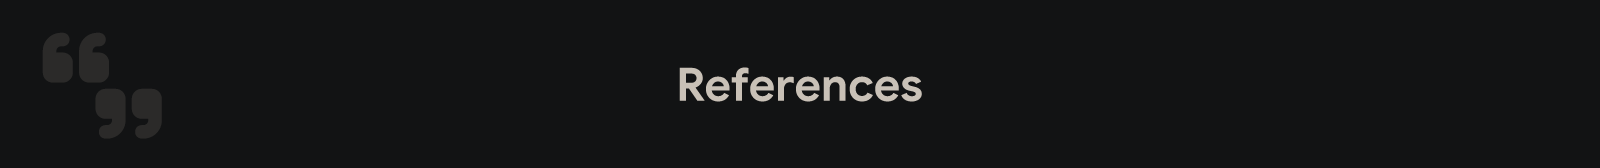

**[1] GHCN-h Data**

- NOAA National Centers for Environmental Information (2025). *Global Historical Climatology Network - hourly (GHCNh).* NOAA/NCEI. https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/

**[2] Software & Services**

- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., & Moore, R. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment, 202*, 18–27. https://doi.org/10.1016/j.rse.2017.06.031

- pycountry contributors. *pycountry: ISO databases for Python* [Software]. https://pypi.org/project/pycountry/

- geonamescache contributors. *geonamescache: Geonames data for Python* [Software]. https://pypi.org/project/geonamescache/ *(country codes from GeoNames, https://www.geonames.org, CC BY 4.0)*

- Muñoz-Sabater, J., Dutra, E., Agustí-Panareda, A., Albergel, C., Arduini, G., Balsamo, G., Boussetta, S., Choulga, M., Harrigan, S., Hersbach, H., Martens, B., Miralles, D.G., Piles, M., Rodríguez-Fernández, N.J., Zsoter, E., Buontempo, C., Thépaut, J.-N., 2021. ERA5-Land: a state-of-the-art global reanalysis dataset for land applications. Earth Syst Sci Data 13, 4349–4383. https://doi.org/10.5194/essd-13-4349-2021

- Samapriya Roy. (2025). samapriya/geeup: geeup: Simple CLI for Earth Engine Uploads (Version 2.0.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.18073520